In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [137]:
df= pd.read_csv("data/processed/asynchrony_per_plot.csv")
fd_df = pd.read_csv("data/final/final_dataset_ba.csv")
PID_df= pd.read_csv('data/lookup/PID_location_v3.csv')
abundance_df = pd.read_parquet('data/final/dataset_rarity.parquet')

fd_df=fd_df.merge(PID_df[['PID','lat','lon', 'biome', 'STDAGE', "percent_conifer"]], on='PID', how='left')
fd_df=fd_df.merge(abundance_df[['PID','pct_rare_species']], on='PID', how='left')
df=df.merge(fd_df[['PID', "Raos_Q", 'Functional_Evenness', 'Species Richness', 'pct_rare_species', "percent_conifer", 'WSCI', 'std npp']], how='left', on='PID') 

df.to_csv("results/merged_diversity_asynchrony.csv", index=False)

In [138]:
df

,PID,n_species,n_years,source_file,phi_LdM,asynchrony_LdM,eta_gross,cv_community,cv_species,log_stab_community,log_stab_species,async_term,Raos_Q,Functional_Evenness,Species Richness,pct_rare_species,percent_conifer,WSCI,std npp
0,1_1_129_106_1,4,4,FIA_AL.arrow,0.119197,0.880803,-0.254749,0.308835,0.894526,1.174948,0.111461,1.063487,1.792630,0.651494,4.0,0.500000,94.439613,9.628735,0.140655
1,1_1_129_107_1,6,4,FIA_AL.arrow,0.707081,0.292919,0.780374,0.260454,0.309740,1.345328,1.172023,0.173305,2.514881,0.740397,6.0,0.166667,9.078066,9.976326,0.121419
2,1_1_129_114_1,9,4,FIA_AL.arrow,0.569886,0.430114,0.433335,0.129420,0.171439,2.044689,1.763529,0.281160,2.253025,0.585720,8.0,0.500000,9.690622,9.859601,0.096428
3,1_1_129_115_1,10,4,FIA_AL.arrow,0.376847,0.623153,0.356423,0.513733,0.836865,0.666052,0.178093,0.487959,1.659012,0.537046,4.0,0.250000,59.264585,9.825285,0.091509
4,1_1_129_120_1,6,4,FIA_AL.arrow,0.962093,0.037907,0.842618,0.863698,0.880549,0.146532,0.127210,0.019322,2.174586,0.671780,6.0,0.666667,71.966280,9.909535,0.132574
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14678,3_50_3_1397_1,9,4,FIA_VT.arrow,0.258767,0.741233,0.222842,0.067898,0.133476,2.689745,2.013831,0.675914,2.828776,0.507208,9.0,0.444444,11.670143,10.106694,0.057094
14679,3_50_3_405_1,6,4,FIA_VT.arrow,0.598238,0.401762,0.135500,0.135959,0.175780,1.995405,1.738522,0.256883,2.901486,0.798200,5.0,0.200000,24.740043,9.825042,0.063317
14680,3_50_3_441_1,9,4,FIA_VT.arrow,0.825751,0.174249,0.705072,0.459685,0.505866,0.777214,0.681483,0.095731,2.637118,0.677096,5.0,0.200000,7.892157,10.210386,0.071536
14681,3_50_3_451_1,5,4,FIA_VT.arrow,0.465343,0.534657,0.497109,0.044200,0.064794,3.119039,2.736548,0.382490,2.588106,0.811543,5.0,0.000000,26.589581,9.937428,0.044755


Species richness: n = 12940 | Spearman rho = 0.445 (p = 0) | Pearson r = 0.441
Rao's Q : n = 12940 | Spearman rho = 0.324 (p = 0) | Pearson r = 0.375
Functional evenness: n = 12940 | Spearman rho = 0.165 (p = 1.1e-79) | Pearson r = 0.232
% rare species: n = 12940 | Spearman rho = 0.111 (p = 5.8e-37) | Pearson r = 0.148
% conifer: n = 12940 | Spearman rho = -0.399 (p = 0) | Pearson r = -0.452
Structural complexity: n = 12940 | Spearman rho = 0.185 (p = 1.6e-99) | Pearson r = 0.071
Stability (SD NPP): n = 12940 | Spearman rho = 0.066 (p = 3.8e-14) | Pearson r = 0.059


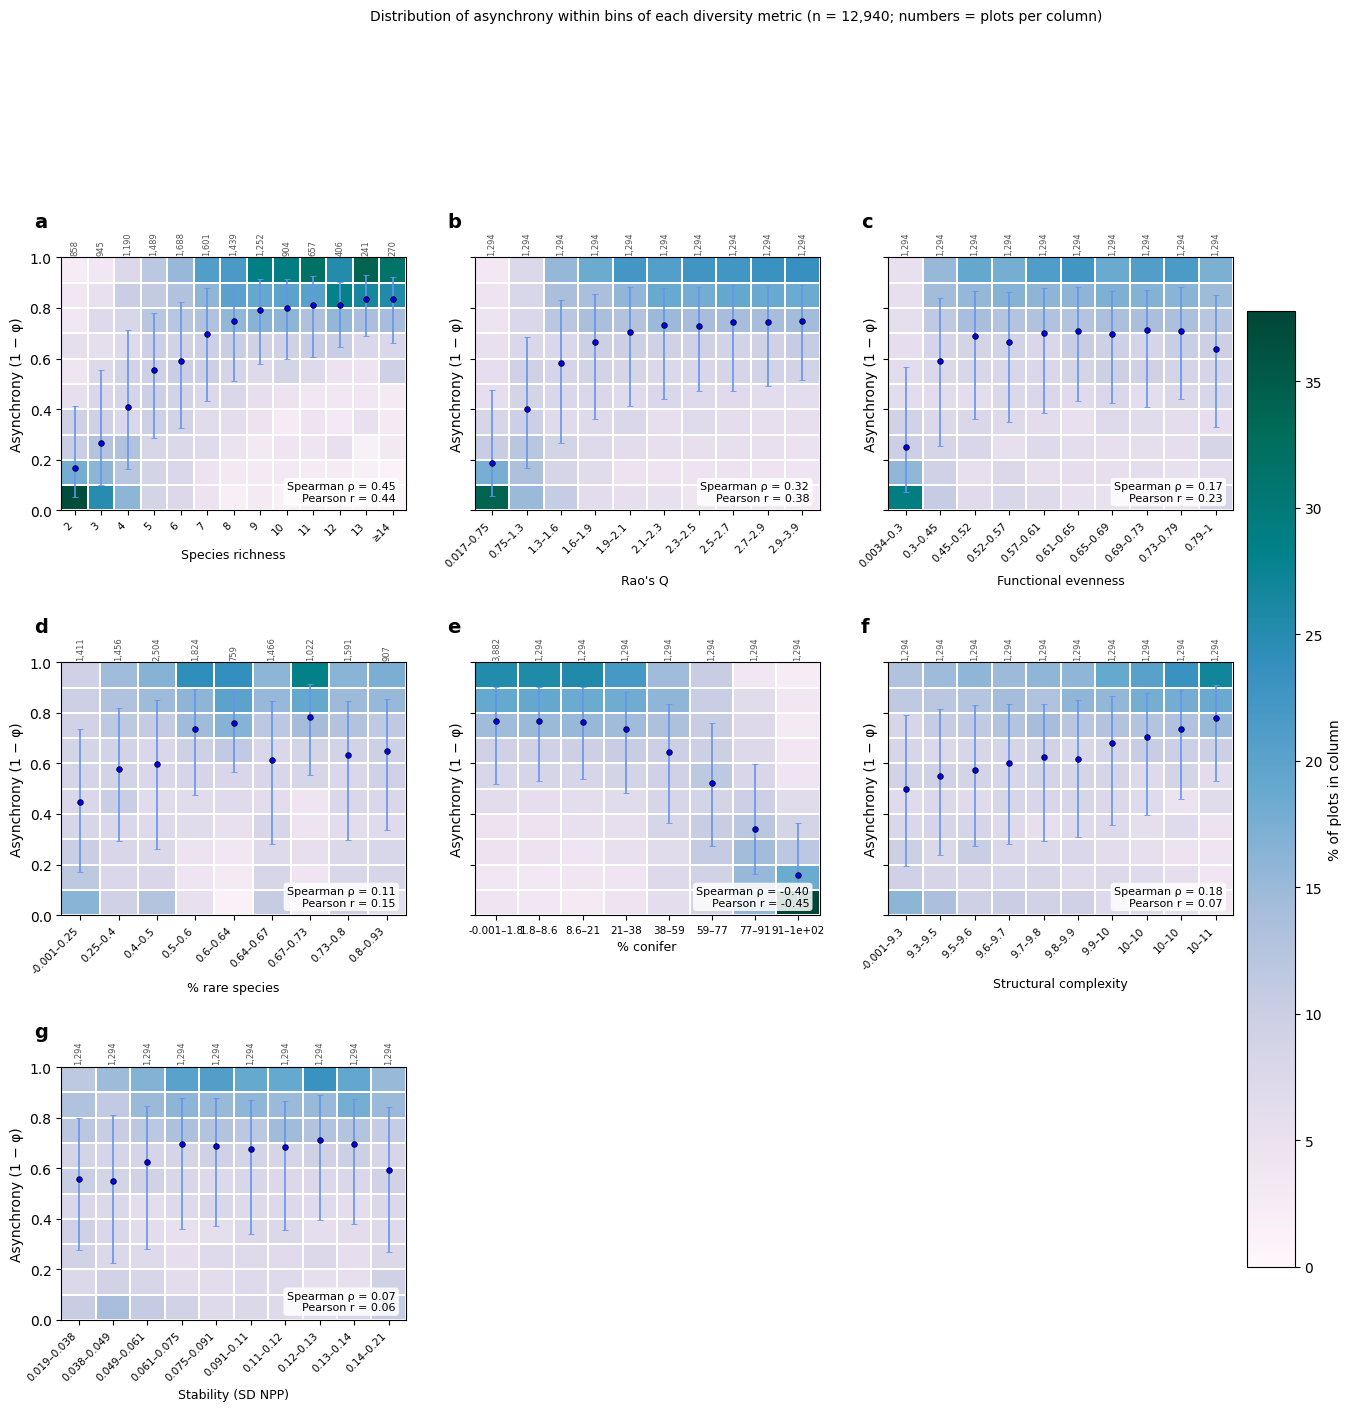

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy import stats

# ---------------------------------------------------------------
# Configuration (set the column names to match your table)
# ---------------------------------------------------------------
PANELS = [  # (column, axis label, discrete?)
    ("Species Richness", "Species richness", True),
    ("Raos_Q", "Rao's Q ", False),
    ("Functional_Evenness", "Functional evenness", False),
    ('pct_rare_species', "% rare species", False),
    ('percent_conifer', "% conifer", False), 
    ('WSCI', "Structural complexity", False), 
    ('std npp', "Stability (SD NPP)", False)
]
Y_COL, Y_LABEL = "asynchrony_LdM", "Asynchrony (1 − φ)"
SPECIES_COL = "n_species"   # from the asynchrony output; used to drop single-species plots
MIN_SPECIES = 2
N_XBINS = 10                # equal-count bins for continuous metrics (10 = deciles)
RICHNESS_CAP_PCT = 99       # richness levels above this percentile are pooled into one "≥" bin
N_YBINS = 10                # asynchrony bands of equal width between 0 and 1
ANNOTATE_CELLS = False      # print the % in each cell
CMAP = "PuBuGn"
OUT = "results/asynchrony_vs_diversity_binned"


def x_bins(d, col, discrete):
    """Bin index per plot and tick labels; columns are drawn equal width."""
    x = d[col].to_numpy(float)
    if discrete:
        cap = int(np.floor(np.percentile(x, RICHNESS_CAP_PCT)))
        lo = int(np.floor(x.min()))
        xi = np.clip(np.round(x).astype(int), lo, cap) - lo
        labels = [str(v) for v in range(lo, cap)] + [f"\u2265{cap}"]
        return xi, labels
    q = pd.qcut(x, N_XBINS, duplicates="drop")
    xi = q.codes
    labels = [f"{iv.left:.2g}\u2013{iv.right:.2g}" for iv in q.categories]
    return xi, labels


def binned_panels(df):
    d = df.copy()
    if SPECIES_COL in d:
        d = d[d[SPECIES_COL] >= MIN_SPECIES]
    d = d.dropna(subset=[Y_COL] + [c for c, _, _ in PANELS]).reset_index(drop=True)
    y = d[Y_COL].to_numpy(float)
    y_edges = np.linspace(0, 1, N_YBINS + 1)
    yi = np.clip(np.digitize(y, y_edges[1:-1]), 0, N_YBINS - 1)

    # Column-normalised shares per panel
    panels = []
    for col, label, disc in PANELS:
        xi, labels = x_bins(d, col, disc)
        k = len(labels)
        counts = np.zeros((N_YBINS, k))
        np.add.at(counts, (yi, xi), 1)
        n_col = counts.sum(axis=0)
        with np.errstate(invalid="ignore", divide="ignore"):
            share = 100 * counts / n_col
        med = np.array([np.median(y[xi == j]) if n_col[j] else np.nan for j in range(k)])
        q25 = np.array([np.quantile(y[xi == j], 0.25) if n_col[j] else np.nan for j in range(k)])
        q75 = np.array([np.quantile(y[xi == j], 0.75) if n_col[j] else np.nan for j in range(k)])
        x = d[col].to_numpy(float)
        rho, p_rho = stats.spearmanr(x, y)
        r, _ = stats.pearsonr(x, y)
        print(f"{label}: n = {len(x)} | Spearman rho = {rho:.3f} (p = {p_rho:.2g}) | Pearson r = {r:.3f}")
        panels.append(dict(label=label, labels=labels, share=share, n_col=n_col,
                           med=med, q25=q25, q75=q75, rho=rho, r=r))

    vmax = np.nanmax([np.nanmax(p["share"]) for p in panels])
    norm = mcolors.Normalize(vmin=0, vmax=vmax)

    ncols = 3
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.6 * nrows), sharey=True)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[len(panels):]:
        ax.set_visible(False)
    for ax, p, letter in zip(axes, panels, "abcdefghjkl"):
        k = len(p["labels"])
        mesh = ax.pcolormesh(np.arange(k + 1), y_edges, p["share"], cmap=CMAP, norm=norm,
                             shading="flat", edgecolors="white", linewidth=0.3)
        if ANNOTATE_CELLS:
            for j in range(k):
                for i in range(N_YBINS):
                    v = p["share"][i, j]
                    if np.isfinite(v) and v >= 1:
                        ax.text(j + 0.5, (y_edges[i] + y_edges[i + 1]) / 2, f"{v:.0f}",
                                ha="center", va="center", fontsize=5.5,
                                color="white" if norm(v) < 0.6 else "black")

        xc = np.arange(k) + 0.5
        ax.errorbar(xc, p["med"], yerr=[p["med"] - p["q25"], p["q75"] - p["med"]],
                    fmt="o", ms=4, color="blue", mec="black", mew=0.6,
                    ecolor="cornflowerblue", elinewidth=1.2, capsize=2, zorder=3,
                    label="Median and IQR")
        for j in range(k):
            ax.text(j + 0.5, 1.01, f"{int(p['n_col'][j]):,}", ha="center", va="bottom",
                    fontsize=6, rotation=90, color="#555555", transform=ax.transData,
                    clip_on=False)

        ax.set_xticks(xc)
        ax.set_xticklabels(p["labels"], rotation=45 if len(p["labels"]) > 8 else 0,
                           ha="right" if len(p["labels"]) > 8 else "center", fontsize=7.5)
        ax.set_xlim(0, k)
        ax.set_ylim(0, 1)
        ax.set_ylabel(Y_LABEL)
        ax.set_xlabel(p["label"], fontsize=9)
        ax.text(0.97, 0.03, f"Spearman \u03c1 = {p['rho']:.2f}\nPearson r = {p['r']:.2f}",
                transform=ax.transAxes, va="bottom", ha="right", fontsize=8,
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="none"))
        ax.text(-0.08, 1.12, letter, transform=ax.transAxes, fontsize=14, fontweight="bold")


    axes[-1].legend(loc="upper right", fontsize=7.5, frameon=True, framealpha=0.85)
    fig.subplots_adjust(hspace=0.6)
    fig.colorbar(mesh, ax=axes, label="% of plots in column", shrink=0.9, pad=0.01)
    fig.suptitle(f"Distribution of asynchrony within bins of each diversity metric "
                 f"(n = {len(d):,}; numbers = plots per column)", fontsize=10, y=1.06)
    fig.savefig(f"{OUT}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT}.pdf", bbox_inches="tight")
    plt.show()

binned_panels(df)